# Chapter 4 — The Backpropagation Algorithm

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mengrenman/artificial_intelligence_engines/blob/main/notebooks/04_backprop.ipynb)

*Companion notebook for Stone (2020), Chapter 4, using `scripts/backprop.py`.*

`BackpropNetwork` is a 3-layer network: inputs → sigmoidal hidden units (Eq 4.1) → linear output units
(Section 4.3: the output units need not be sigmoidal). Bias is an extra input fixed at $-1$ (Fig 4.2).

Forward pass: $z_j = \sigma\big(\sum_i w_{ij}x_i\big)$, $\;y_k = \sum_j w_{jk}z_j$.
Error: $E = \tfrac12\sum_k (y_k - \mathsf{y}_k)^2$ (Eq 4.8), averaged over the training set.

Backward pass:
* output delta $\delta_k = y_k - \mathsf{y}_k$ (Eq 4.16), gradient $\partial E/\partial w_{jk} = \delta_k z_j$;
* hidden delta $\delta_j = z_j(1-z_j)\sum_k w_{jk}\delta_k$ (Eq 4.27), gradient $\partial E/\partial w_{ij} = \delta_j x_i$;
* update $\Delta w = -\epsilon\,\partial E/\partial w$ (Eq 4.37).

In [1]:
# Colab setup: install the companion package (does nothing when run locally).
try:
    import google.colab  # noqa: F401
    %pip install -q git+https://github.com/mengrenman/artificial_intelligence_engines
except ImportError:
    pass

In [2]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scripts.backprop import BackpropNetwork
from aie.data import xor_dataset
from aie.gradcheck import numerical_gradient, relative_error

## Solving XOR (Section 4.2, Fig 4.6)

The XOR problem that defeated the perceptron (Eq 3.5–3.6) is solved by a 2-2-1 network.

x = [-1. -1.]  target = -1  output = -1.0000
x = [1. 1.]  target = -1  output = -1.0000
x = [-1.  1.]  target = +1  output = +1.0000
x = [ 1. -1.]  target = +1  output = +1.0000
final E = 3.28e-30


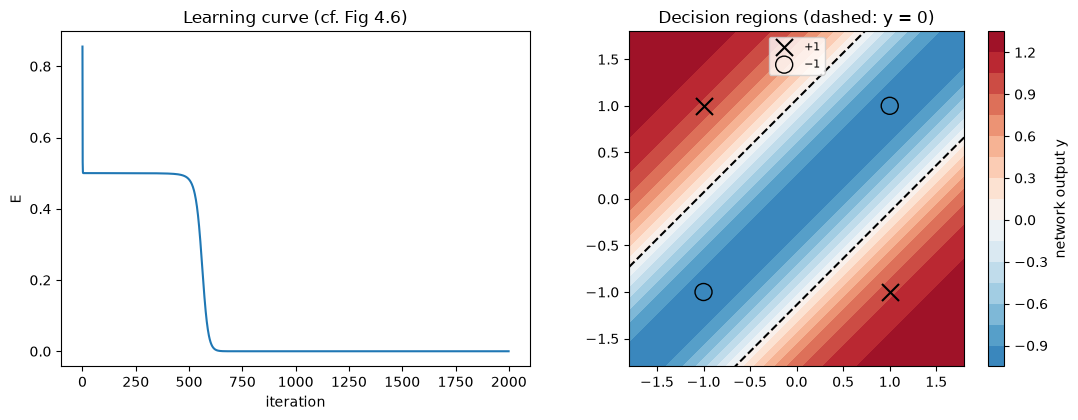

In [3]:
X, t = xor_dataset()
T = t[:, None]
net = BackpropNetwork(2, 2, 1, lr=0.5, seed=0).fit(X, T, n_epochs=2000)
Y, Z = net.forward(X)
for x, tt, yy in zip(X, t, Y.ravel()):
    print(f"x = {x}  target = {tt:+.0f}  output = {yy:+.4f}")
print(f"final E = {net.history[-1]:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
axes[0].plot(net.history); axes[0].set_xlabel("iteration"); axes[0].set_ylabel("E")
axes[0].set_title("Learning curve (cf. Fig 4.6)")
g = np.linspace(-1.8, 1.8, 200)
G1, G2 = np.meshgrid(g, g)
out = net.predict(np.column_stack([G1.ravel(), G2.ravel()])).reshape(G1.shape)
cf = axes[1].contourf(G1, G2, out, levels=20, cmap="RdBu_r", vmin=-1.5, vmax=1.5)
axes[1].contour(G1, G2, out, levels=[0], colors="k", linestyles="--")
fig.colorbar(cf, ax=axes[1], label="network output y")
pos = t > 0
axes[1].scatter(*X[pos].T, marker="x", s=150, color="k", label="+1")
axes[1].scatter(*X[~pos].T, s=150, facecolors="none", edgecolors="k", label="−1")
axes[1].set_aspect("equal"); axes[1].legend(loc="upper center", fontsize=8)
axes[1].set_title("Decision regions (dashed: y = 0)"); fig.tight_layout()

Unlike a perceptron, the network carves the input space into a non-convex region (a band between two
lines), so opposite corners get the same label.

### What the hidden units learn

The hidden layer re-represents each input $\mathbf{x}$ as $\mathbf{z} = (z_1, z_2)$. In hidden-unit space the four
XOR patterns become **linearly separable**, so the linear output unit — effectively a perceptron on $\mathbf{z}$ —
can separate them with a straight line, $w_1 z_1 + w_2 z_2 - b = 0$.

hidden states Z:
 [[0.119 0.084]
 [0.119 0.084]
 [0.88  0.001]
 [0.002 0.883]]


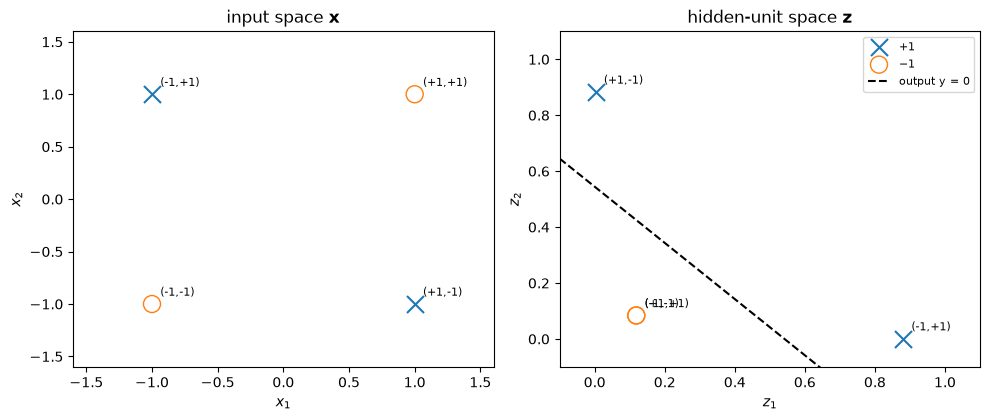

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
for ax, P, ttl, lab in [(axes[0], X, "input space $\\mathbf{x}$", ("$x_1$", "$x_2$")),
                        (axes[1], Z, "hidden-unit space $\\mathbf{z}$", ("$z_1$", "$z_2$"))]:
    ax.scatter(*P[pos].T, marker="x", s=150, color="C0", label="+1")
    ax.scatter(*P[~pos].T, s=150, facecolors="none", edgecolors="C1", label="−1")
    for p_, x in zip(P, X):
        ax.annotate(f"({x[0]:+.0f},{x[1]:+.0f})", p_, textcoords="offset points", xytext=(6, 6), fontsize=8)
    ax.set_title(ttl); ax.set_xlabel(lab[0]); ax.set_ylabel(lab[1])
w1, w2, b = net.W2[0]
zs = np.linspace(-0.1, 1.1, 10)
axes[1].plot(zs, (b - w1 * zs) / w2, "k--", label="output y = 0")
axes[1].set_xlim(-0.1, 1.1); axes[1].set_ylim(-0.1, 1.1); axes[1].legend(fontsize=8)
axes[0].set_xlim(-1.6, 1.6); axes[0].set_ylim(-1.6, 1.6)
fig.tight_layout()
print("hidden states Z:\n", Z.round(3))

## Gradient check

Backprop bugs are silent: a network with a slightly wrong gradient often still learns, just badly. We compare
the analytic gradients from `gradients()` with central finite differences
$\partial E/\partial w \approx [E(w+h)-E(w-h)]/2h$ computed by `aie.gradcheck.numerical_gradient`.
A relative error around $10^{-9}$–$10^{-10}$ means the backward pass is correct.

In [5]:
rng = np.random.default_rng(0)
Xg, Tg = rng.normal(size=(10, 3)), rng.normal(size=(10, 2))
chk = BackpropNetwork(3, 4, 2, seed=1)
gW1, gW2, E = chk.gradients(Xg, Tg)
f = lambda: chk.error(Xg, Tg)
nW1 = numerical_gradient(f, chk.W1)
nW2 = numerical_gradient(f, chk.W2)
print(f"E = {E:.6f}")
print(f"relative error dE/dW1: {relative_error(gW1, nW1):.2e}")
print(f"relative error dE/dW2: {relative_error(gW2, nW2):.2e}")

E = 1.064467
relative error dE/dW1: 5.38e-10
relative error dE/dW2: 1.29e-10


## Sigmoidal output units and 0/1 targets (Figs 4.5–4.6)

The book's XOR example uses sigmoidal hidden **and** output units with targets of 0 or 1, and reports
convergence in under 40 iterations. `BackpropNetwork(..., output="sigmoid")` multiplies the output delta
by $f'(u) = y(1-y)$ (Eq 4.16). Note that our learning rate multiplies the *mean* error gradient over the
4 patterns, so `lr=20` here corresponds to a per-pattern rate of 5. Convergence speed depends strongly on
the initial weights; many seeds take a few hundred iterations, and some get stuck in a local minimum.

outputs after 50 iterations: [0.138 0.865 0.902 0.12 ]  targets: [0. 1. 1. 0.]


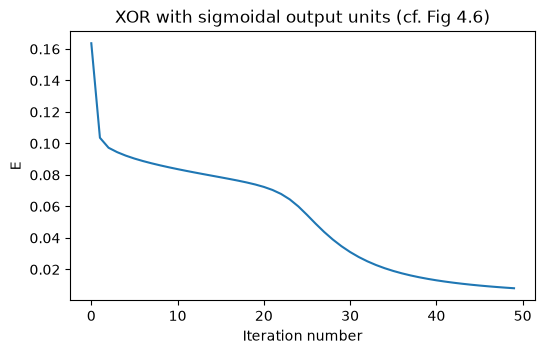

In [6]:
from aie.data import xor_dataset_01
X01, t01 = xor_dataset_01()
T01 = t01[:, None]
sig = BackpropNetwork(2, 2, 1, lr=20.0, seed=13, weight_scale=2.0, output="sigmoid")
sig.fit(X01, T01, n_epochs=50)
print("outputs after 50 iterations:", np.round(sig.predict(X01).ravel(), 3), " targets:", t01)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(sig.history)
ax.set_xlabel("Iteration number"); ax.set_ylabel("E")
ax.set_title("XOR with sigmoidal output units (cf. Fig 4.6)")
plt.show()

## Different random initial weights

Different seeds give different (often "inscrutable", as the book says) final weights, but most converge.
Occasionally a run stalls on a plateau or in a local minimum (Section 4.7).

Text(0.5, 1.0, 'XOR learning curves from 10 random initialisations')

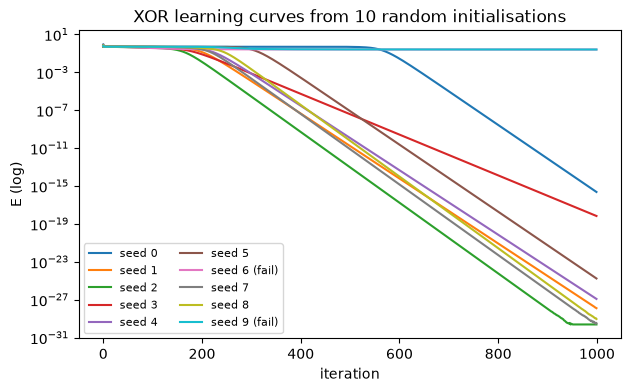

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for s in range(10):
    n = BackpropNetwork(2, 2, 1, lr=0.5, seed=s).fit(X, T, n_epochs=1000)
    ok = np.all(np.sign(n.predict(X).ravel()) == t)
    ax.semilogy(n.history, label=f"seed {s}" + ("" if ok else " (fail)"))
ax.set_xlabel("iteration"); ax.set_ylabel("E (log)"); ax.legend(ncol=2, fontsize=8)
ax.set_title("XOR learning curves from 10 random initialisations")

## Number of hidden units and learning rate

Cybenko's theorem (Section 4.3) says one hidden layer suffices in principle, but not how many units.
For XOR, one hidden unit is not enough; two suffice; more units make learning faster and more reliable.
The learning rate trades speed against stability: too small is slow, too large can overshoot or stall.

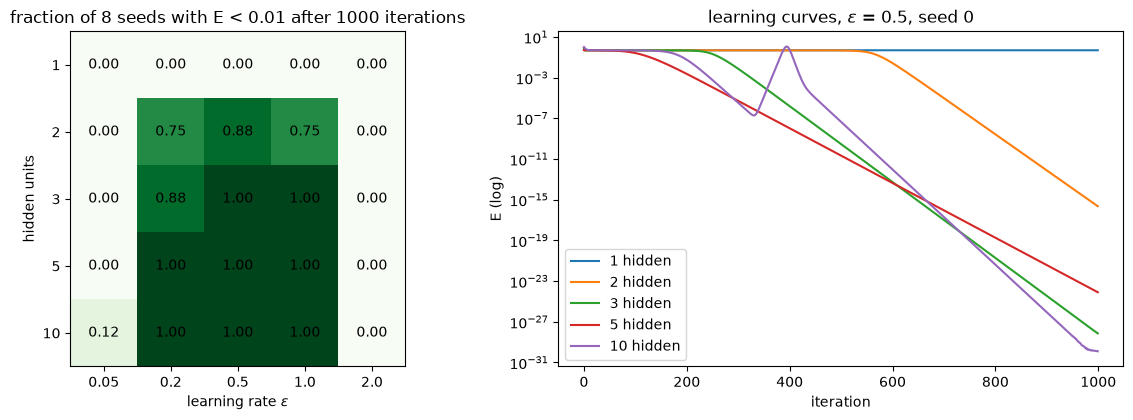

In [8]:
hidden = [1, 2, 3, 5, 10]
lrs = [0.05, 0.2, 0.5, 1.0, 2.0]
seeds = range(8)
success = np.zeros((len(hidden), len(lrs)))
np.seterr(over="ignore")            # large learning rates can saturate the sigmoid
for i, h in enumerate(hidden):
    for j, lr in enumerate(lrs):
        for s in seeds:
            n = BackpropNetwork(2, h, 1, lr=lr, seed=s).fit(X, T, n_epochs=1000)
            success[i, j] += n.history[-1] < 0.01 and np.all(np.sign(n.predict(X).ravel()) == t)
success /= len(seeds)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
im = axes[0].imshow(success, cmap="Greens", vmin=0, vmax=1)
axes[0].set_xticks(range(len(lrs)), lrs); axes[0].set_yticks(range(len(hidden)), hidden)
axes[0].set_xlabel("learning rate $\\epsilon$"); axes[0].set_ylabel("hidden units")
for i in range(len(hidden)):
    for j in range(len(lrs)):
        axes[0].text(j, i, f"{success[i, j]:.2f}", ha="center", va="center")
axes[0].set_title("fraction of 8 seeds with E < 0.01 after 1000 iterations")
for h in hidden:
    n = BackpropNetwork(2, h, 1, lr=0.5, seed=0).fit(X, T, n_epochs=1000)
    axes[1].semilogy(n.history, label=f"{h} hidden")
axes[1].set_xlabel("iteration"); axes[1].set_ylabel("E (log)"); axes[1].legend()
axes[1].set_title("learning curves, $\\epsilon$ = 0.5, seed 0"); fig.tight_layout()

## Summary

* Backprop computes all weight gradients of a multi-layer network in one backward sweep of delta terms (Eq 4.16, 4.27).
* Hidden units transform the inputs into a representation in which the problem is linearly separable, which is why
  a 2-2-1 network solves XOR.
* The analytic gradient matches a numerical gradient to ~$10^{-9}$, confirming the derivation.
* Results depend on initialisation, number of hidden units and learning rate.

*Note:* the autoencoder / image-denoising examples belong to later chapters (Section 6.8 and Chapter 7),
so they are not reproduced here.